## Mathematical Model

\begin{align}
    \text{max} ~~ & x + y \\
    \text{s.t.}~~ & 6*x+4*y \le 24 \\
                  & x+2*y \le 6 \\
                  & y-x \le 1 \\
                  & y \le 2 \\
                  & x, y \ge 0
                  

\end{align}

In [ ]:
# pip install gekko
from gekko import GEKKO
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Model
m = GEKKO()

# Vars
x,y = m.Array(m.Var, 2, lb=0)
y.UPPER = 2

# Constraints
m.Equations([6*x+4*y<=24, 
             x+2*y <=6, 
             y-x<=1])

# Obj Fct
m.Maximize(x+y)


In [8]:
# Solve
m.solve()
# m.solve(disp=False)

 ----------------------------------------------------------------
 APMonitor, Version 1.0.3
 APMonitor Optimization Suite
 ----------------------------------------------------------------
 
 
 --------- APM Model Size ------------
 Each time step contains
   Objects      :            0
   Constants    :            0
   Variables    :            5
   Intermediates:            0
   Connections  :            0
   Equations    :            4
   Residuals    :            4
 
 Number of state variables:              5
 Number of total equations: -            3
 Number of slack variables: -            3
 ---------------------------------------
 Degrees of freedom       :             -1
 
 * Warning: DOF <= 0
 solver            3  not supported
 using default solver: APOPT
 ----------------------------------------------
 Steady State Optimization with APOPT Solver
 ----------------------------------------------
 
 Iter    Objective  Convergence
    0 -4.35897E+00  3.00000E+00
    1 -4.50000E+0

In [ ]:
print(x.value[0], y.value[0])
print(-m.options.objfcnval) # '-' bc the solver change it to min fct when solves the optim pb

3.0 1.5
4.5


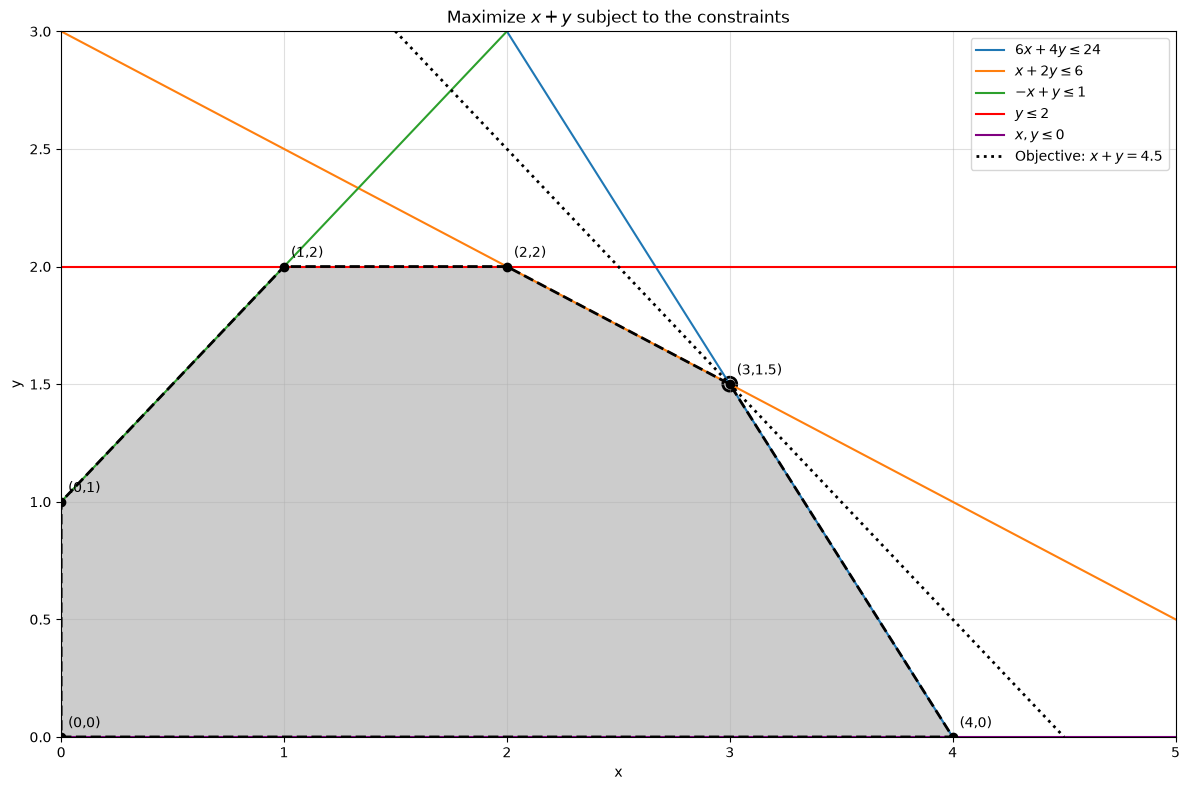

In [21]:
# Visulization 
plt.figure(figsize=(12, 8))
x = np.linspace(0, 5, 500)

# Constraint boundaries
plt.plot(x, 6 - 1.5*x, label=r'$6x+4y\leq24$')
plt.plot(x, 3 - 0.5*x, label=r'$x+2y\leq6$')
plt.plot(x, x + 1, label=r'$-x+y\leq1$')
plt.axhline(2, color='red', label=r'$y\leq2$')
plt.axhline(0, color='purple', label=r'$x, y\leq0$')

# Feasible region
vertices = np.array([
    [0, 0], [4, 0], [3, 1.5],
    [2, 2], [1, 2], [0, 1]
])

plt.fill(vertices[:, 0], vertices[:, 1],
         color='gray', alpha=0.4)

# Dashed boundary
closed = np.vstack([vertices, vertices[0]])
plt.plot(closed[:, 0], closed[:, 1], 'k--', linewidth=2)

# Label vertices
for px, py in vertices:
    plt.scatter(px, py, color='black', zorder=5)
    plt.annotate(
        f'({px:g},{py:g})',
        (px, py),
        xytext=(5, 7),
        textcoords='offset points'
    )

# Objective function at optimum: x + y = 4.5
x_obj = np.linspace(0, 4.5, 200)
plt.plot(x_obj, 4.5 - x_obj, 'k:', linewidth=2,
         label=r'Objective: $x+y=4.5$')

plt.scatter(3, 1.5, s=100, facecolors='none',
            edgecolors='black', linewidths=2)

plt.xlim(0, 5)
plt.ylim(0, 3)
plt.xticks(np.arange(0, 5.1, 1))
plt.yticks(np.arange(0, 3.1, 0.5))
plt.xlabel('x')
plt.ylabel('y')
plt.title(r'Maximize $x+y$ subject to the constraints')
plt.grid(True, alpha=0.4)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()